# Particle filters
From the book *Bayesian Methods for Autonomous Robotics and Intelligent Infrastructure Systems* by Khalid M. Mosalam.

Companion to **Particle Filters**, including **Detailed Computational Walkthrough (Small Example)**; the final dynamic example also compares with the **Extended Kalman Filter (EKF)**.

All numerical examples use synthetic or illustrative data.

Run top to bottom. Dependencies: NumPy and Matplotlib.

Figure styling: Ziad Mosalam. Run all cells from this notebook directory. Each figure is displayed below its calculation and exported to `../figures/` as PDF and PNG. The original simulation and estimation calculations are unchanged.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.ticker import MultipleLocator

plt.style.use('book.mplstyle')
Path('../figures').mkdir(exist_ok=True)

BLUE = '#003262'
GOLD = '#B17A00'
TEAL = '#247C86'
INK = '#30363B'
GRAY = '#7D858B' 

np.random.seed(42)

### 1D Robot Localization Using Particle Filter

In [2]:
np.random.seed(42)  # Seed this example independently of other notebooks.
N = 100
particles = np.random.uniform(0, 10, N)
weights = np.ones(N) / N
z = 7

for i in range(N):
    particles[i] += np.random.normal(0, 0.5)
    weights[i] = np.exp(-0.5 * ((particles[i] - z)**2))

weights /= np.sum(weights)
indices = np.random.choice(np.arange(N), size=N, p=weights)
particles = particles[indices]
estimate = np.mean(particles)
print("Estimated Position:", estimate)

Estimated Position: 7.030129555527797


### Particle filter and EKF comparison (nonlinear measurement)

In [3]:
# Basic Particle Filter Loop
def particle_filter_step(particles, weights, motion_fn, sensor_fn, z):
    # Predict
    particles = [motion_fn(p) for p in particles]
    # Update
    weights = [sensor_fn(p, z) for p in particles]
    weights = normalize(weights)
    # Resample
    new_particles = systematic_resample(particles, weights)
    return new_particles

# Kalman Gain
def kalman_gain(P, R, H=1.0):
    return (P * H) / (H * P * H + R)

In [4]:
def normalize(w):
    w = np.asarray(w, dtype=float)
    s = np.sum(w)
    return (w / s) if s > 0 else np.full_like(w, 1.0 / len(w))

def systematic_resample(particles, weights):
    N = len(particles)
    positions = (np.arange(N) + np.random.rand()) / N
    indexes = np.zeros(N, dtype=int)
    cumsum = np.cumsum(weights)
    i = j = 0
    while i < N:
        if positions[i] < cumsum[j]:
            indexes[i] = j
            i += 1
        else:
            j += 1
    return [particles[idx] for idx in indexes]

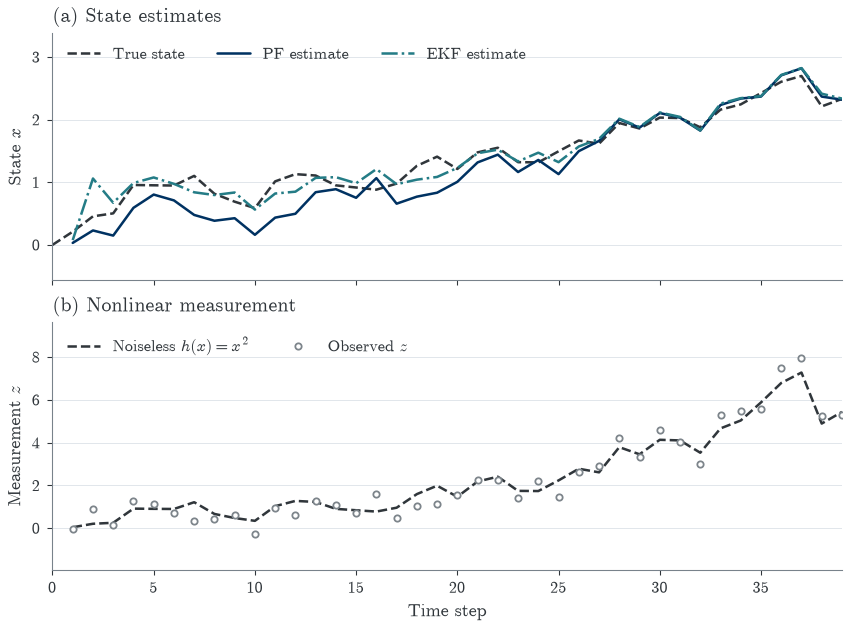

In [5]:
############ Problem setup (1D) ############
np.random.seed(42)
T = 40
u = 0.1                 # constant control
Q = 0.05                # process noise variance
R = 0.20                # measurement noise variance
x_true = np.zeros(T)
z_obs  = np.zeros(T)

x_true[0] = 0.0
for k in range(1, T):
    # state: x_{k+1} = x_k + u + w
    x_true[k] = x_true[k-1] + u + np.random.normal(0, np.sqrt(Q))
    # measurement: z_k = x_k^2 + v   <-- NONLINEAR
    z_obs[k]  = x_true[k]**2 + np.random.normal(0, np.sqrt(R))

############ Particle filter ############
N_particles = 500
particles = list(np.random.normal(0.0, 1.0, size=N_particles))  # prior
weights   = normalize(np.ones(N_particles))

def motion_fn(p):
    return p + u + np.random.normal(0, np.sqrt(Q))

def gaussian_likelihood(error, var):
    return np.exp(-0.5 * error**2 / var) / np.sqrt(2*np.pi*var)

def sensor_fn(p, z):
    # z ~ N(p^2, R) -> likelihood of observing z given state p
    return gaussian_likelihood(z - (p**2), R)

pf_est = []

############ 1D Extended Kalman Filter (nonlinear measurement) ############
def h(x):
    # measurement function
    return x**2

def H_jac(x):
    # Jacobian dh/dx at x
    return 2.0 * x

x_hat = 0.0
P = 1.0
kf_est = []

for k in range(1, T):

    ###### Particle filter step ######
    particles = particle_filter_step(particles, weights, motion_fn, sensor_fn, z_obs[k])
    weights = normalize(np.ones(N_particles))  # after resampling, reset equal weights
    pf_est.append(np.mean(particles))

    ###### EKF step ######
    # Predict
    x_hat_pred = x_hat + u
    P_pred = P + Q
    # Update (nonlinear: z = h(x) = x^2)
    z_pred = h(x_hat_pred)
    H = H_jac(x_hat_pred)
    K = kalman_gain(P_pred, R, H)   # scalar gain
    x_hat = x_hat_pred + K * (z_obs[k] - z_pred)
    P = (1 - K * H) * P_pred
    kf_est.append(x_hat)

############ Visualization ############
# The raw observations are not state coordinates: z = x squared + noise.
fig, axes = plt.subplots(2, 1, figsize=(6.5, 4.8), sharex=True,
                         layout='constrained')
axes[0].plot(range(T), x_true, color=INK, linestyle='--', label='True state')
axes[0].plot(range(1, T), pf_est, color=BLUE, label='PF estimate')
axes[0].plot(range(1, T), kf_est, color=TEAL, linestyle='-.', label='EKF estimate')
axes[0].set_title('(a) State estimates', loc='left')
axes[0].set_ylabel('State $x$')
axes[0].legend(ncol=3, loc='upper left')

axes[1].plot(range(1, T), x_true[1:]**2, color=INK, linestyle='--',
             label='Noiseless $h(x)=x^2$')
axes[1].plot(range(1, T), z_obs[1:], linestyle='none', marker='o',
             markersize=3.5, markerfacecolor='white', markeredgecolor=GRAY,
             label='Observed $z$')
axes[1].set_title('(b) Nonlinear measurement', loc='left')
axes[1].set(xlabel='Time step', ylabel='Measurement $z$', xlim=(0, T-1))
axes[1].legend(ncol=2, loc='upper left')
axes[1].xaxis.set_major_locator(MultipleLocator(5))
for ax in axes:
    ax.margins(y=0.20)
    ax.grid(axis='y')
fig.savefig('../figures/particle-filters-comparison.pdf', metadata={'CreationDate': None, 'ModDate': None})
fig.savefig('../figures/particle-filters-comparison.png', dpi=200)
plt.show()

## Detailed Computational Walkthrough (Small Example)

This walkthrough follows the small example in the **Particle Filters** chapter. We reproduce the book's published realization rather than drawing different particles.

The initial and predicted positions are fixed to the book's table. Their differences are one listed realization of process noise with nominal standard deviation 0.5. The measurement is $z=7$ with sensor noise standard deviation 1. The resampled indices below are exactly the fixed, zero-based indices in the book's code box.

In [6]:
# Initial and predicted positions from the book's small example.
x_initial = np.array([0.5, 2.1, 3.8, 5.0, 5.9, 6.3, 7.1, 7.8, 8.5, 9.2])
x_pred = np.array([0.375, 2.551, 4.032, 5.099, 5.556,
                   6.592, 7.271, 7.940, 8.646, 9.324])
z = 7
N_small = len(x_pred)

print("Initial and predicted particle positions")
print(f"{'Index':>5} {'Initial Position':>18} {'Predicted Position':>20}")
for i, (xi, xp) in enumerate(zip(x_initial, x_pred), start=1):
    print(f"{i:5d} {xi:18.1f} {xp:20.3f}")


Initial and predicted particle positions
Index   Initial Position   Predicted Position
    1                0.5                0.375
    2                2.1                2.551
    3                3.8                4.032
    4                5.0                5.099
    5                5.9                5.556
    6                6.3                6.592
    7                7.1                7.271
    8                7.8                7.940
    9                8.5                8.646
   10                9.2                9.324


### Measurement likelihoods and normalized weights

For equal prior weights, $\tilde w_i=(2\pi)^{-1/2}\exp[-(x_{{\rm pred},i}-7)^2/2]$ and $w_i=\tilde w_i/\sum_j\tilde w_j$. Calculations retain full precision; table entries use three significant digits, as in the book.

In [7]:
likelihoods = np.zeros(N_small)
for i in range(N_small):
    likelihoods[i] = 1 / np.sqrt(2 * np.pi) * np.exp(-0.5 * (x_pred[i] - z)**2)
weights_small = likelihoods / np.sum(likelihoods)

print("Gaussian measurement likelihoods for predicted particles")
print(f"{'Index':>5} {'Position':>10} {'Unnormalized Weight':>23} {'Normalized Weight':>21}")
for i, (xp, likelihood, weight) in enumerate(zip(x_pred, likelihoods, weights_small), start=1):
    print(f"{i:5d} {xp:10.3f} {likelihood:23.2e} {weight:21.2e}")

weighted_mean = np.dot(weights_small, x_pred)
print(f"\nWeighted mean before resampling: {weighted_mean:.15f}")
print(f"Book rounding: {weighted_mean:.4f}")


Gaussian measurement likelihoods for predicted particles
Index   Position     Unnormalized Weight     Normalized Weight
    1      0.375                1.18e-10              8.71e-11
    2      2.551                2.01e-05              1.49e-05
    3      4.032                4.88e-03              3.61e-03
    4      5.099                6.55e-02              4.86e-02
    5      5.556                1.41e-01              1.04e-01
    6      6.592                3.67e-01              2.72e-01
    7      7.271                3.85e-01              2.85e-01
    8      7.940                2.56e-01              1.90e-01
    9      8.646                1.03e-01              7.63e-02
   10      9.324                2.68e-02              1.99e-02

Weighted mean before resampling: 7.063086058310658
Book rounding: 7.0631


### Apply the documented resampling outcome

The index set is fixed for exact table reproduction. It represents one possible multinomial resampling draw, not the unique or most likely draw. Every resampled particle has weight $1/N=0.1$.

The next table's normalized likelihoods are reference values only; they are **not** the particle weights after resampling.

In [8]:
fixed_indices = np.array([6, 6, 7, 6, 6, 7, 7, 4, 4, 5])
x_resampled = x_pred[fixed_indices]
equal_weights = np.ones(N_small) / N_small
resampled_likelihoods = 1 / np.sqrt(2 * np.pi) * np.exp(-0.5 * (x_resampled - z)**2)
normalized_reference = resampled_likelihoods / resampled_likelihoods.sum()

print("Fixed zero-based resampled indices:", fixed_indices)
print("\nLikelihoods of resampled particles (particle weights remain equal)")
print(f"{'Index':>5} {'Position':>10} {'Gaussian Likelihood':>23} {'Normalized Likelihood (reference)':>36}")
for i, (xp, likelihood, reference) in enumerate(zip(x_resampled, resampled_likelihoods, normalized_reference), start=1):
    print(f"{i:5d} {xp:10.3f} {likelihood:23.2e} {reference:36.2e}")

resampled_mean = np.mean(x_resampled)
print(f"\nParticle weight after resampling: {equal_weights[0]:.1f}")
print(f"Sample mean after the fixed resampling draw: {resampled_mean:.4f}")


Fixed zero-based resampled indices: [6 6 7 6 6 7 7 4 4 5]

Likelihoods of resampled particles (particle weights remain equal)
Index   Position     Gaussian Likelihood    Normalized Likelihood (reference)
    1      7.271                3.85e-01                             1.30e-01
    2      7.271                3.85e-01                             1.30e-01
    3      7.940                2.56e-01                             8.68e-02
    4      7.271                3.85e-01                             1.30e-01
    5      7.271                3.85e-01                             1.30e-01
    6      7.940                2.56e-01                             8.68e-02
    7      7.940                2.56e-01                             8.68e-02
    8      5.556                1.41e-01                             4.76e-02
    9      5.556                1.41e-01                             4.76e-02
   10      6.592                3.67e-01                             1.24e-01

Particle weight

The weighted mean before resampling is **7.0631**; the equal-weight mean for this fixed draw is **7.0608**. Their small difference reflects finite-sample resampling variation. All three small-example tables are printed above.